In [81]:
import os
import re
import warnings
import sys
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import umap
from adjustText import adjust_text
from pandas.errors import PerformanceWarning
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
from src import blosum_of, save_plot

# Predicting sensitivity and resistance


In [82]:
CLASSES = ["sensitivity", "neutral", "resistance"]
CLASS_INDEX = {name: position for position, name in enumerate(CLASSES)}
CLASS_COLOUR = {"sensitivity": "#009ADE", "neutral": "#9aa0a6", "resistance": "#FF1F5B"}
CATEGORY_ORDER = [
    "Missense", "Silent", "Nonsense", "Splice-donor", "Splice-acceptor", "Intron", "UTR",
]
CATEGORY_COLOUR = dict(
    zip(
        CATEGORY_ORDER,
        ["#009ADE", "#9aa0a6", "#FF1F5B", "#3f8f6b", "#7b5aa6", "#d1702a", "#1f4e76"],
    )
)

In [83]:
FOLDS, DRAWS, SEEDS, TREES, BOOTSTRAPS = 5, 10, 3, 400, 1000
REPEATS = DRAWS * SEEDS
print(f"run: {FOLDS}-fold CV, {DRAWS} neutral draws, "
      f"{SEEDS} fold partitions -> {REPEATS} repeats, {TREES} trees")

run: 5-fold CV, 10 neutral draws, 3 fold partitions -> 30 repeats, 400 trees


## The modelling table


In [84]:
samples = pd.read_excel(C.DATA / "samplesheet.xlsx", sheet_name="Samples")
compound_of = {
    (row.study, row.cell_line, row.arm): row.compound
    for row in samples[samples.arm_kind == "drug"].itertuples()
}
EDIT_KEY = ["chromosome", "position", "genomic_ref", "genomic_alt"]

In [ ]:
def unambiguous(study):
    annotation = pd.read_csv(C.dataset_file(study, "annotation"), low_memory=False)
    counts = (
        annotation.drop_duplicates(["guide", "editor", *EDIT_KEY])
        .groupby(["guide", "editor"])
        .size()
    )
    single = counts[counts == 1].index
    keep = pd.MultiIndex.from_arrays([annotation.guide, annotation.editor]).isin(single)
    return annotation[keep].drop_duplicates(["guide", "editor"])

In [ ]:
def modelling_table(study):
    variants = unambiguous(study)
    hits = pd.read_csv(C.dataset_file(study, "hits"))
    table = hits[hits.condition.str.endswith("_vs_untreated")].copy()
    left = table.condition.str.split("_vs_").str[0].str.split("_")
    table["cell_line"] = left.str[0]
    table["editor"] = np.where(left.str.len() == 3, left.str[1], "CBE")
    table["arm"] = np.where(left.str.len() == 3, left.str[2], left.str[1])
    # the guide is unambiguous for the editor that scored it, so both key the join
    table = table.merge(variants, on=["guide", "editor"], how="inner")
    table["compound"] = [
        compound_of.get((study, cell, arm))
        for cell, arm in zip(table.cell_line, table.arm)
    ]
    table["category"] = table.codon_mutation_category
    return table

In [87]:
training = modelling_table(C.THIS_STUDY)
print(f"{training.guide.nunique():,} unambiguous sgRNAs, {len(training):,} rows")
print("classes:", training.call.value_counts().to_dict())

13,892 unambiguous sgRNAs, 83,352 rows
classes: {'neutral': 82352, 'resistance': 721, 'sensitivity': 279}


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3698707438.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["compound"] = [
/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3698707438.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["category"] = table.codon_mutation_category


In [88]:
pd.crosstab(training.cell_line, training.compound)

compound,SCH772984,linsitinib,pictilisib
cell_line,,,
A375,13892,13892,13892
HT29,13892,13892,13892


## Feature groups


In [ ]:
cell_context = pd.read_csv(C.DATA / "features_cell_context.csv")
gene_drug = pd.read_csv(C.DATA / "features_gene_drug.csv")
structure = pd.read_csv(C.DATA / "features_variant_structure.csv")
drug_context = pd.read_csv(C.DATA / "features_drug_context.csv")
baseline = drug_context.drop_duplicates(["cell_line", "compound"])[
    ["cell_line", "compound", "ln_ic50"]
]

In [90]:
PROTVAR_FEATURES = [
    "foldx_ddg", "plddt", "pocket_buriedness", "pocket_score",
    "in_predicted_pocket", "interface_count", "interface_max_pdockq", "is_in_interface",
]
CELL_FEATURES = [
    "expression_tpm_log2", "copy_number", "crispr_gene_effect", "protein_abundance",
]
DRUG_FEATURES = ["ln_ic50", "string_distance", "is_drug_target"]
STRUCTURE_KEYS = ["gene", "residue", "wild_type", "mutant"]

In [91]:
def attach_features(table):
    """Join the context and structure blocks without changing the row count."""
    pair = table.vep_Amino_acids.astype(str).str.split("/", n=1, expand=True)
    table = table.assign(
        wild_type=pair[0],
        mutant=pair[1] if pair.shape[1] > 1 else np.nan,
        residue=pd.to_numeric(
            table.vep_Protein_position.astype(str).str.split("-").str[0], errors="coerce"
        ).astype("Int64"),
    )
    before = len(table)
    table = (
        table.merge(cell_context, on=["cell_line", "gene"], how="left")
        .merge(baseline, on=["cell_line", "compound"], how="left")
        .merge(gene_drug, on=["compound", "gene"], how="left")
        .merge(
            structure[STRUCTURE_KEYS + PROTVAR_FEATURES].drop_duplicates(STRUCTURE_KEYS),
            on=STRUCTURE_KEYS,
            how="left",
        )
    )
    assert len(table) == before, f"a merge changed the rows: {before} -> {len(table)}"
    return table

In [ ]:
def vep_block(frame, columns=None, coverage=0.2):
    """Numeric VEP and dbNSFP columns, with consequence and impact one-hot encoded."""
    
    numeric = {}
    
    for column in [c for c in frame.columns if c.startswith("vep_")]:
        values = pd.to_numeric(frame[column], errors="coerce")
        keep = columns is not None or (
            values.notna().mean() >= coverage and values.nunique() > 1
        )
        if keep:
            numeric[column] = values
    
    block = pd.DataFrame(numeric, index=frame.index)
    block["blosum62"] = blosum_of(frame.vep_aaref, frame.vep_aaalt)
    
    consequence = frame.vep_Consequence.astype(str).str.split(",").str[0]
    
    block = block.join(pd.get_dummies(consequence, prefix="consequence", dtype=float))
    block = block.join(
        pd.get_dummies(frame.vep_IMPACT.astype(str), prefix="impact", dtype=float)
    )
    
    block = block.join(
        pd.get_dummies(frame.vep_am_class, prefix="am_class", dtype=float)
    )
    return block if columns is None else block.reindex(columns=columns, fill_value=0.0)

In [ ]:
def with_features(table, columns=None):
    table = attach_features(table)
    block = vep_block(table, columns=columns)
    table = table.drop(columns=[c for c in block.columns if c in table.columns])
    table = pd.concat([table, block], axis=1)
    assert not table.columns.duplicated().any(), "duplicate feature columns"
    return table, list(block.columns)

In [ ]:
training, BUILT_VEP_FEATURES = with_features(training)

# notebook 03 selects the annotation features
SELECTED = pd.read_csv(C.DATA / "features_selected.csv", index_col=0)
available = set(training.columns)
selected_columns = [n if n in available else f"vep_{n}" for n in SELECTED.index]
missing = [c for c in selected_columns if c not in available]
assert not missing, f"notebook 03 kept features this notebook never built: {missing}"

PROTVAR_SELECTED = [c for c in selected_columns if c in PROTVAR_FEATURES]
SPLICE_SELECTED = [c for c in selected_columns if c.startswith("spliceai_")]

DUMMY_FEATURES = [
    c for c in BUILT_VEP_FEATURES
    if c.startswith(("consequence_", "impact_", "am_class_"))
]
RAW_VEP_FEATURES = [
    c for c in selected_columns if c not in PROTVAR_SELECTED + SPLICE_SELECTED
] + DUMMY_FEATURES

print(f"{len(selected_columns)} features from notebook 03 "
      f"({len(SPLICE_SELECTED)} splice, {len(PROTVAR_SELECTED)} structural) "
      f"plus {len(DUMMY_FEATURES)} one-hot columns")
print(SELECTED.family.value_counts().to_string())

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3661213753.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table = table.assign(


56 features from notebook 03 (4 splice, 2 structural) plus 19 one-hot columns
family
pathogenicity    32
conservation      9
frequency         8
splice            4
structure         2
other             1


In [95]:
training["edit"] = (
    training.chromosome.astype(str)
    + ":"
    + training.position.astype(str)
    + training.genomic_ref.astype(str)
    + ">"
    + training.genomic_alt.astype(str)
)
GROUP_UNIT = "edit"

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/115813437.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  training["edit"] = (


In [96]:
per_edit = training.groupby("edit").guide.nunique()
print(f"{training.guide.nunique():,} guides install {len(per_edit):,} distinct edits")
print(f"{int((per_edit > 1).sum()):,} edits come from more than one guide")

13,892 guides install 10,399 distinct edits
2,832 edits come from more than one guide


### Columns that are not mechanistic

Transcript positions let the model memorise where the hits sit in each gene, and database
record identifiers mark variants already catalogued as pathogenic.


In [ ]:
POSITIONAL = re.compile(
    r"(^|_)(pos|position|chr|start|end|coordinate|aapos|codonpos|cds|cdna|"
    r"spliceai_dp_|residue|strand|Allele|exon|intron_rank|HGVS|Feature|Codons|"
    r"uniparc|refseq|Ensembl|transcript|UNIPROT|SWISSPROT|TREMBL|"
    r"clinvar|pubmed|omim|orphanet)|(^|_)id$",
    re.I,
)
DATABASE_FLAGS = {"vep_PHENO", "vep_SOMATIC"}
MECHANISTIC_PREFIXES = ("consequence_", "impact_", "am_class_")

In [98]:
def non_mechanistic(column):
    if column.startswith(MECHANISTIC_PREFIXES):
        return False
    stem = column.replace("vep_", "")
    return bool(POSITIONAL.search(stem)) or column in DATABASE_FLAGS

### Splice features


In [99]:
SPLICE_DELTAS = SPLICE_SELECTED
SPLICE_SCORED = "splice_scored"
training[SPLICE_SCORED] = training[SPLICE_DELTAS].notna().any(axis=1).astype(float)
training[SPLICE_DELTAS] = training[SPLICE_DELTAS].fillna(0.0)
SPLICE_FEATURES = SPLICE_DELTAS + [SPLICE_SCORED]
print(f"{len(SPLICE_DELTAS)} splice deltas, unscored in "
      f"{1 - training[SPLICE_SCORED].mean():.2%} of rows")

4 splice deltas, unscored in 0.02% of rows


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3295738654.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  training[SPLICE_SCORED] = training[SPLICE_DELTAS].notna().any(axis=1).astype(float)


In [100]:
VEP_FEATURES = [c for c in RAW_VEP_FEATURES if not non_mechanistic(c)]
PROTVAR_KEPT = [c for c in PROTVAR_SELECTED if not non_mechanistic(c)]
ANNOTATION_FEATURES = VEP_FEATURES + SPLICE_FEATURES
PERTURBATION_FEATURES = ANNOTATION_FEATURES + PROTVAR_KEPT
CONTEXT_FEATURES = CELL_FEATURES + DRUG_FEATURES
ALL_FEATURES = PERTURBATION_FEATURES + CONTEXT_FEATURES
DISCARDED = [c for c in RAW_VEP_FEATURES if non_mechanistic(c)]

In [101]:
FEATURE_SETS = {
    "Full model": ALL_FEATURES,
    "Cellular": CONTEXT_FEATURES,
    "Annotation": ANNOTATION_FEATURES,
    "ProtVar": PROTVAR_KEPT,
    "Perturbation": PERTURBATION_FEATURES,
}
pd.DataFrame({"features": {name: len(columns) for name, columns in FEATURE_SETS.items()}})

,features
Full model,83
Cellular,7
Annotation,74
ProtVar,2
Perturbation,76


In [102]:
pd.DataFrame(
    {"features": {
        "cellular and drug context": len(CONTEXT_FEATURES),
        "annotation": len(ANNOTATION_FEATURES),
        "  of which splice": len(SPLICE_FEATURES),
        "ProtVar structure": len(PROTVAR_KEPT),
        "full model": len(ALL_FEATURES),
        "discarded as non-mechanistic": len(DISCARDED),
    }}
)

,features
cellular and drug context,7
annotation,74
of which splice,5
ProtVar structure,2
full model,83
discarded as non-mechanistic,0


## Exported design matrices


In [ ]:
KEYS = ["guide", "edit", "gene", "cell_line", "compound", "editor", "category"]

training["row_id"] = np.arange(len(training))
X = training.set_index("row_id")[ALL_FEATURES].astype(float)
y = training.set_index("row_id")[KEYS + ["call"]]
print(f"X {X.shape[0]:,} x {X.shape[1]}, y {y.call.value_counts().to_dict()}, "
      f"joined on row_id")

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/1044196958.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  training["row_id"] = np.arange(len(training))


X 83,352 x 83, y {'neutral': 82352, 'resistance': 721, 'sensitivity': 279}, joined on row_id


In [ ]:
GROUP_OF = [
    ("cellular", CELL_FEATURES),
    ("drug", DRUG_FEATURES),
    ("annotation", ANNOTATION_FEATURES),
    ("protvar", PROTVAR_KEPT),
]
dictionary = pd.DataFrame(
    {
        "feature": ALL_FEATURES,
        "group": [
            next((name for name, columns in GROUP_OF if column in columns), "other")
            for column in ALL_FEATURES
        ],
    }
).set_index("feature")
dictionary["coverage"] = X.notna().mean().reindex(dictionary.index).to_numpy()
dictionary["distinct"] = X.nunique().reindex(dictionary.index).to_numpy()
dictionary.group.value_counts().rename("features").to_frame()

,features
group,
annotation,74
cellular,4
drug,3
protvar,2


In [156]:
X.to_csv(C.DATA / "model_matrix_X.csv")
y.to_csv(C.DATA / "model_matrix_y.csv")
dictionary.to_csv(C.DATA / "model_matrix_features.csv")

## Downsampling neutral class


In [ ]:
def downsample(frame, draw):
    called = frame[frame.call != "neutral"]
    neutral = frame[frame.call == "neutral"]
    target = int(frame.call.value_counts().iloc[1])
    fraction = min(1.0, target / len(neutral))
    generator = np.random.default_rng(draw)
    chosen = []
    for positions in neutral.groupby(["gene", "cell_line"]).indices.values():
        wanted = min(len(positions), max(1, int(round(len(positions) * fraction))))
        chosen.append(generator.choice(positions, size=wanted, replace=False))
    return pd.concat([called, neutral.iloc[np.concatenate(chosen)]], ignore_index=True)

In [107]:
balanced = downsample(training, 0)
print("after one draw:", balanced.call.value_counts().to_dict())

after one draw: {'neutral': 724, 'resistance': 721, 'sensitivity': 279}


## Cross-validation


### Hyperparameters

Chosen by `local/hyperparameter_search.py`.


In [108]:
UNTUNED = {
    "max_depth": 6, "learning_rate": 0.05, "n_estimators": 400, "min_child_weight": 1,
    "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 1.0, "gamma": 0.0,
}
INTEGER = {"max_depth", "n_estimators", "min_child_weight"}
SEARCH_FILE = C.DATA / "model_hyperparameter_search.csv"
search = (
    pd.read_csv(SEARCH_FILE).sort_values("resistance", ascending=False).reset_index(drop=True)
    if SEARCH_FILE.exists()
    else None
)
PARAMETERS = dict(UNTUNED) if search is None else {
    name: int(search.at[0, name]) if name in INTEGER else float(search.at[0, name])
    for name in UNTUNED
}
print(f"{'untuned' if search is None else 'tuned'} configuration: {PARAMETERS}")

tuned configuration: {'max_depth': 8, 'learning_rate': 0.02, 'n_estimators': 400, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 0.5, 'gamma': 1.0}


In [109]:
SEARCH_COLUMNS = [*UNTUNED, "sensitivity", "neutral", "resistance", "macro", "is_default"]
search[SEARCH_COLUMNS].head(8).rename(lambda rank: f"rank {rank + 1}")

,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,gamma,sensitivity,neutral,resistance,macro,is_default
rank 1,8,0.02,400,3,0.8,0.6,0.5,1.0,0.755758,0.720575,0.810478,0.762270,False
rank 2,8,0.02,200,1,0.6,0.8,0.5,0.0,0.755724,0.713689,0.807985,0.759133,False
rank 3,6,0.05,800,1,1.0,0.4,1.0,1.0,0.753920,0.718332,0.805562,0.759271,False
rank 4,6,0.05,200,3,1.0,0.8,0.5,1.0,0.752364,0.721440,0.805076,0.759627,False
rank 5,8,0.05,200,10,1.0,0.4,1.0,1.0,0.753370,0.716597,0.804229,0.758065,False
rank 6,8,0.02,800,10,1.0,0.4,5.0,1.0,0.748920,0.723083,0.803469,0.758491,False
rank 7,8,0.02,200,10,0.6,0.8,5.0,1.0,0.735732,0.716027,0.803117,0.751625,False
rank 8,8,0.02,400,10,1.0,0.6,1.0,0.0,0.755128,0.715732,0.802800,0.757886,False


In [110]:
untuned_rank = int(search.is_default.idxmax())
print(search.loc[[untuned_rank, 0], ["resistance", "macro"]]
      .set_axis(["untuned", "tuned"]).to_string())
print(f"gain: {search.at[0, 'resistance'] - search.at[untuned_rank, 'resistance']:+.4f} "
      f"resistance; the untuned configuration ranked {untuned_rank + 1} of {len(search)}")

         resistance    macro
untuned    0.796297  0.75188
tuned      0.810478  0.76227
gain: +0.0142 resistance; the untuned configuration ranked 18 of 41


In [111]:
def fit_model(features, labels, seed):
    return XGBClassifier(
        objective="multi:softprob", num_class=len(CLASSES), tree_method="hist",
        n_jobs=-1, random_state=seed, verbosity=0, **PARAMETERS,
    ).fit(features, labels)

In [112]:
def out_of_fold(columns, draw, seed, group=GROUP_UNIT, frame=None):
    """Out-of-fold probabilities for one neutral draw and one fold partition."""
    block = downsample(training if frame is None else frame, draw).reset_index(drop=True)
    labels = block.call.map(CLASS_INDEX).to_numpy()
    features = block[columns].astype(float).to_numpy()
    probability = np.zeros((len(block), len(CLASSES)))
    # a design with fewer groups than folds becomes leave-one-group-out, which is what
    # holding out a drug means when the screen used only three compounds
    splits = min(FOLDS, block[group].nunique())
    splitter = StratifiedGroupKFold(splits, shuffle=True, random_state=seed)
    for train, test in splitter.split(features, labels, groups=block[group]):
        probability[test] = fit_model(features[train], labels[train], seed).predict_proba(
            features[test]
        )
    return block, labels, probability

In [113]:
def auprc_by_class(labels, probability):
    """Average precision for each class, one against the rest."""
    return {
        name: average_precision_score(
            (labels == index).astype(int), probability[:, index]
        )
        for name, index in CLASS_INDEX.items()
    }

In [114]:
def repeated(columns, group=GROUP_UNIT, frame=None):
    """Per-repeat AUPRC, the pooled confusion matrix, and the pooled predictions."""
    levels = (training if frame is None else frame)[group].nunique()
    if levels < FOLDS:
        print(f"  {group}: {levels} groups, so {levels}-fold leave-one-out")
    rows, matrix, truths, scores = [], np.zeros((len(CLASSES), len(CLASSES))), [], []
    for seed, draw in product(range(SEEDS), range(DRAWS)):
        labels, probability = out_of_fold(columns, draw, seed, group, frame)[1:]
        rows.append({"seed": seed, "draw": draw, **auprc_by_class(labels, probability)})
        matrix += confusion_matrix(
            labels, probability.argmax(axis=1), labels=range(len(CLASSES))
        )
        truths.append(labels)
        scores.append(probability)
    return {
        "scores": pd.DataFrame(rows),
        "confusion": matrix,
        "truth": np.concatenate(truths),
        "probability": np.vstack(scores),
    }

## Baselines


In [115]:
def baseline_auprc(labels, kind, seed=0):
    """AUPRC per class for a predictor that ignores the features."""
    generator = np.random.default_rng(seed)
    scores = {}
    for name, index in CLASS_INDEX.items():
        truth = (labels == index).astype(int)
        if kind == "constant":
            predicted = np.full(len(labels), truth.mean())
        elif kind == "uniform":
            predicted = generator.random(len(labels))
        else:
            raise ValueError(kind)
        scores[name] = average_precision_score(truth, predicted)
    return scores

In [116]:
reference_labels = downsample(training, 0).call.map(CLASS_INDEX).to_numpy()
baselines = pd.DataFrame(
    {
        "Constant": baseline_auprc(reference_labels, "constant"),
        "Uniform random": baseline_auprc(reference_labels, "uniform"),
    }
).T
baselines

,sensitivity,neutral,resistance
Constant,0.161833,0.419954,0.418213
Uniform random,0.156185,0.436145,0.430161


## Average precision by feature set


In [117]:
evaluated = {name: repeated(columns) for name, columns in FEATURE_SETS.items()}
per_set = {name: result["scores"] for name, result in evaluated.items()}
confusions = {name: result["confusion"] for name, result in evaluated.items()}
auprc = pd.DataFrame({name: frame[CLASSES].mean() for name, frame in per_set.items()}).T
auprc["features"] = [len(FEATURE_SETS[name]) for name in auprc.index]
auprc

,sensitivity,neutral,resistance,features
Full model,0.743641,0.723885,0.803383,83
Cellular,0.682502,0.711274,0.754968,7
Annotation,0.419258,0.621804,0.674353,74
ProtVar,0.255835,0.458481,0.490302,2
Perturbation,0.421817,0.626468,0.675785,76


In [118]:
spread = pd.DataFrame({name: frame[CLASSES].std() for name, frame in per_set.items()}).T
print(f"standard deviation over {REPEATS} repeats")
spread

standard deviation over 30 repeats


,sensitivity,neutral,resistance
Full model,0.013483,0.010110,0.008996
Cellular,0.021688,0.011668,0.006225
Annotation,0.016534,0.011225,0.013647
ProtVar,0.013127,0.012377,0.018653
Perturbation,0.015569,0.011327,0.013163


### Confusion matrices


In [119]:
shares = {
    name: pd.DataFrame(matrix / matrix.sum(axis=1, keepdims=True),
                       index=CLASSES, columns=CLASSES)
    for name, matrix in confusions.items()
}
accuracy = {name: np.trace(matrix) / matrix.sum() for name, matrix in confusions.items()}
pd.Series(accuracy, name="accuracy").to_frame()

,accuracy
Full model,0.704950
Cellular,0.697506
Annotation,0.601218
ProtVar,0.478519
Perturbation,0.601566


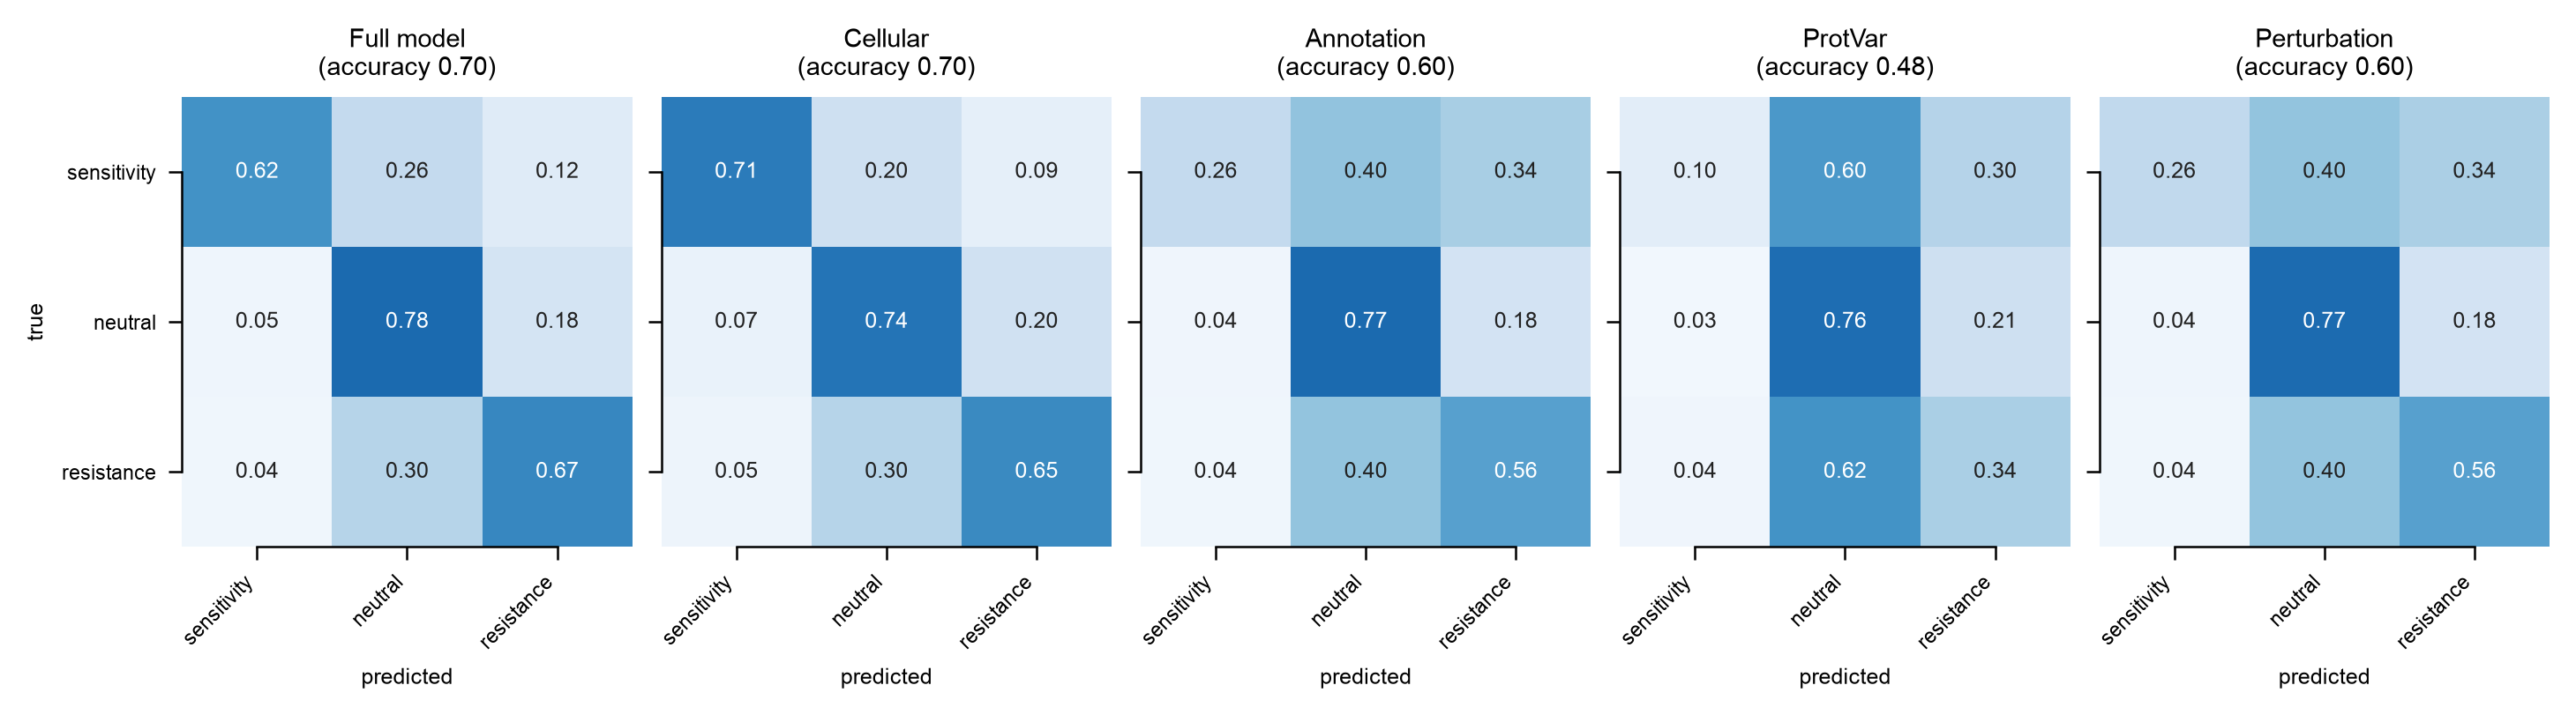

In [120]:
fig, axes = plt.subplots(1, len(shares), figsize=(9.6, 2.3))
for ax, (name, frame) in zip(axes, shares.items()):
    ax.imshow(frame, cmap="Blues", vmin=0, vmax=1)
    for (row, column), value in np.ndenumerate(frame.to_numpy()):
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=6,
                color="white" if value > 0.5 else "#222222")
    ax.set_xticks(range(len(CLASSES)), CLASSES, fontsize=5.5, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES if ax is axes[0] else [], fontsize=5.5)
    ax.set_title(f"{name}\n(accuracy {accuracy[name]:.2f})", fontsize=7)
    ax.set_xlabel("predicted", fontsize=6)
axes[0].set_ylabel("true", fontsize=6)
fig.tight_layout(pad=0.3)
save_plot(fig, "model_confusion_by_feature_set")
plt.show()

### Precision-recall curves


In [157]:
pooled_truth = evaluated["Full model"]["truth"]
pooled_score = evaluated["Full model"]["probability"]
print(f"{len(pooled_truth):,} out-of-fold predictions pooled over {REPEATS} repeats")

51,720 out-of-fold predictions pooled over 30 repeats


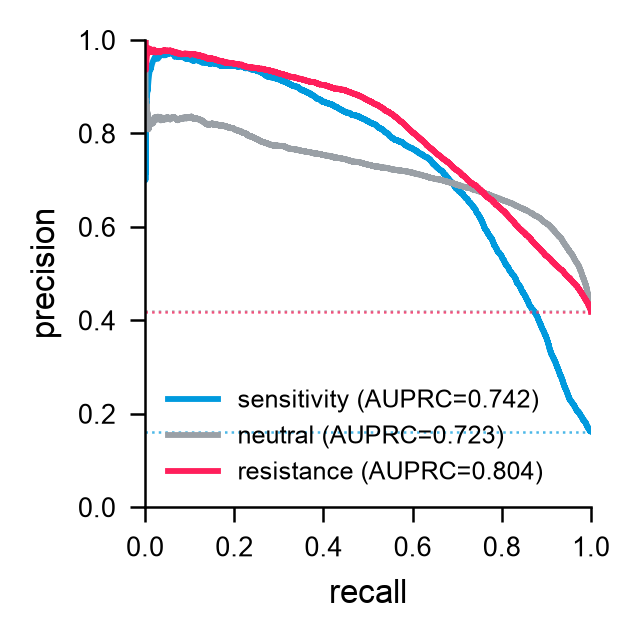

In [160]:
fig, ax = plt.subplots(figsize=(2, 2))
for name, index in CLASS_INDEX.items():
    truth = (pooled_truth == index).astype(int)
    precision, recall, _ = precision_recall_curve(truth, pooled_score[:, index])
    score = average_precision_score(truth, pooled_score[:, index])
    ax.plot(recall, precision, color=CLASS_COLOUR[name], lw=1.4,
            label=f"{name} (AUPRC={score:.3f})")
    ax.axhline(truth.mean(), color=CLASS_COLOUR[name], lw=0.6, ls=":", alpha=0.7)
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=6, loc="lower left")
ax.tick_params(labelsize=6.5)
fig.tight_layout(pad=0.3)
save_plot(fig, "model_pr_curves")
plt.show()

### Average precision against the baselines


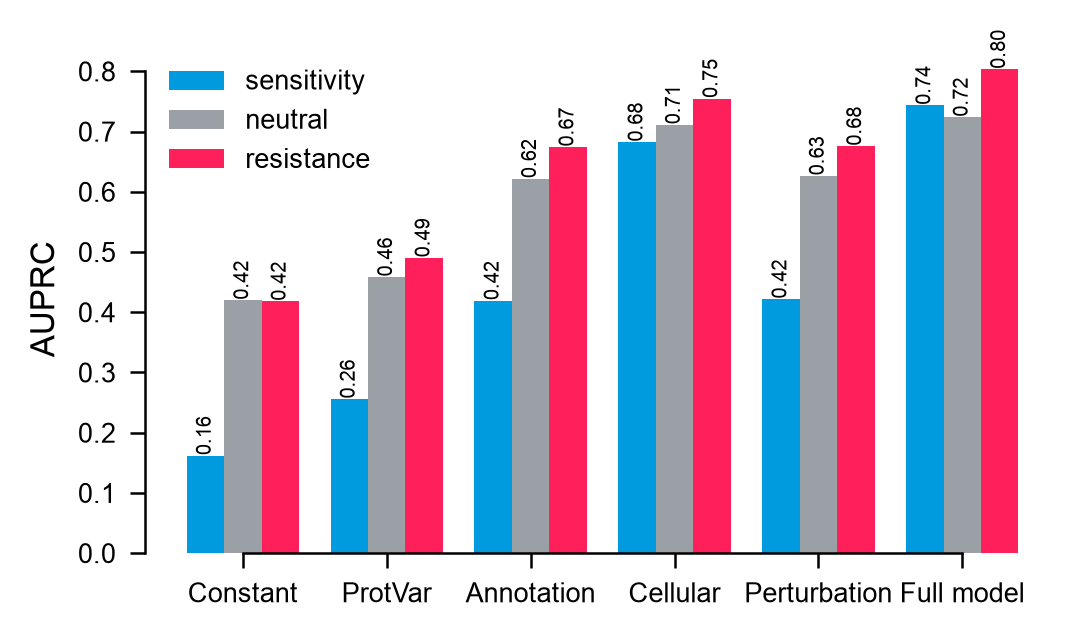

In [164]:
bars = pd.concat([baselines, auprc[CLASSES]])
ORDER = ["Constant", "ProtVar", "Annotation", "Cellular",
         "Perturbation", "Full model"]
bars = bars.reindex([name for name in ORDER if name in bars.index])

fig, ax = plt.subplots(figsize=(3.5, 2))
width = 0.26
positions = np.arange(len(bars))
for offset, name in zip([-width, 0, width], CLASSES):
    ax.bar(positions + offset, bars[name], width=width, color=CLASS_COLOUR[name],
           label=name, linewidth=0)
    for position, value in zip(positions + offset, bars[name]):
        ax.text(position, value + 0.008, f"{value:.2f}", ha="center", fontsize=4.8,
                rotation=90)
ax.set_xticks(positions)
ax.set_xticklabels(bars.index, rotation=0, ha="center", fontsize=6)
ax.set_ylabel("AUPRC")

ax.legend(frameon=False, fontsize=6.5, ncol=1, loc="upper left")
ax.tick_params(labelsize=6.5)
fig.tight_layout(pad=0.3)
save_plot(fig, "model_auprc_by_feature_set")
plt.show()

## External validation


In [127]:
external = modelling_table(C.COELHO_STUDY)
external = external[
    (external.cell_line == "HT29")
    & (external.editor == "CBE")
    & (external.compound.isin(["pictilisib", "trametinib"]))
].copy()
external, _ = with_features(external, columns=RAW_VEP_FEATURES)
print(f"{len(external):,} rows over {external.guide.nunique():,} sgRNAs")
print("classes:", external.call.value_counts().to_dict())
print("compounds:", external.compound.value_counts().to_dict())

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3698707438.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["compound"] = [
/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3698707438.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  table["category"] = table.codon_mutation_category


15,694 rows over 7,847 sgRNAs
classes: {'neutral': 15634, 'sensitivity': 37, 'resistance': 23}
compounds: {'pictilisib': 7847, 'trametinib': 7847}


In [ ]:
for column in SPLICE_DELTAS:
    if column not in external.columns:
        external[column] = np.nan

external[SPLICE_SCORED] = external[SPLICE_DELTAS].notna().any(axis=1).astype(float)
external[SPLICE_DELTAS] = external[SPLICE_DELTAS].fillna(0.0)

print(f"splice unscored in {1 - external[SPLICE_SCORED].mean():.2%} of external rows")

splice unscored in 20.85% of external rows


In [129]:
external["edit"] = (
    external.chromosome.astype(str)
    + ":"
    + external.position.astype(str)
    + external.genomic_ref.astype(str)
    + ">"
    + external.genomic_alt.astype(str)
)
shared = set(training.edit) & set(external.edit)
print(f"{len(shared):,} of {external.edit.nunique():,} external edits also appear in "
      f"training ({len(shared) / external.edit.nunique():.1%})")

1,870 of 5,843 external edits also appear in training (32.0%)


In [ ]:
external_labels = external.call.map(CLASS_INDEX).to_numpy()
external_matrix = external[ALL_FEATURES].astype(float).to_numpy()
external_probabilities = []

for seed in range(SEEDS):
    for draw in range(DRAWS):
        block = downsample(training, draw)
        model = fit_model(
            block[ALL_FEATURES].astype(float).to_numpy(),
            block.call.map(CLASS_INDEX).to_numpy(),
            seed,
        )
        external_probabilities.append(model.predict_proba(external_matrix))

print(f"{len(external_probabilities)} fitted models scored on {len(external):,} external rows")

30 fitted models scored on 15,694 external rows


### At the natural class balance


In [131]:
prevalence = {
    name: float((external_labels == index).mean()) for name, index in CLASS_INDEX.items()
}
raw_rows = []
for probability in external_probabilities:
    predicted = probability.argmax(axis=1)
    row = {}
    for name, index in CLASS_INDEX.items():
        truth = external_labels == index
        call = predicted == index
        row[f"{name} precision"] = (
            float((truth & call).sum() / call.sum()) if call.sum() else np.nan
        )
        row[f"{name} recall"] = float((truth & call).sum() / truth.sum())
        row[f"{name} called"] = int(call.sum())
    raw_rows.append(row)
raw = pd.DataFrame(raw_rows)

In [132]:
natural = pd.DataFrame(
    {
        "prevalence": prevalence,
        "support": {name: int((external_labels == index).sum())
                    for name, index in CLASS_INDEX.items()},
        "precision": {name: raw[f"{name} precision"].mean() for name in CLASSES},
        "recall": {name: raw[f"{name} recall"].mean() for name in CLASSES},
        "rows called": {name: raw[f"{name} called"].mean() for name in CLASSES},
        "auprc": {
            name: np.mean([
                average_precision_score((external_labels == index).astype(int),
                                        probability[:, index])
                for probability in external_probabilities
            ])
            for name, index in CLASS_INDEX.items()
        },
    }
)
natural["auprc over prevalence"] = natural.auprc / natural.prevalence
natural

,prevalence,support,precision,recall,rows called,auprc,auprc over prevalence
sensitivity,0.002358,37,0.017653,0.678378,1456.633333,0.074236,31.488148
neutral,0.996177,15634,0.998700,0.738218,11556.400000,0.998965,1.002799
resistance,0.001466,23,0.004708,0.539130,2680.966667,0.069876,47.680076


### Downsampled to the internal balance


In [133]:
EXTERNAL_DRAWS = 20
external.loc[:, "position"] = np.arange(len(external))

down_rows = []
for probability in external_probabilities:
    for draw in range(EXTERNAL_DRAWS):
        kept = downsample(external, draw).position.to_numpy()
        down_rows.append(auprc_by_class(external_labels[kept], probability[kept]))
external_auprc = pd.DataFrame(down_rows)
print(f"{len(downsample(external, 0)):,} rows per draw, "
      f"{downsample(external, 0).call.value_counts().to_dict()}")

98 rows per draw, {'neutral': 38, 'sensitivity': 37, 'resistance': 23}


In [134]:
external_auprc.describe().loc[["mean", "std"]]

,sensitivity,neutral,resistance
mean,0.795183,0.713860,0.592344
std,0.021242,0.033989,0.033037


In [135]:
means = external_auprc[CLASSES].mean()
errors = external_auprc[CLASSES].std()
down_prevalence = downsample(external, 0).call.value_counts(normalize=True).reindex(CLASSES)
pd.DataFrame({"auprc": means, "s.d.": errors, "prevalence": down_prevalence})

,auprc,s.d.,prevalence
sensitivity,0.795183,0.021242,0.377551
neutral,0.713860,0.033989,0.387755
resistance,0.592344,0.033037,0.234694


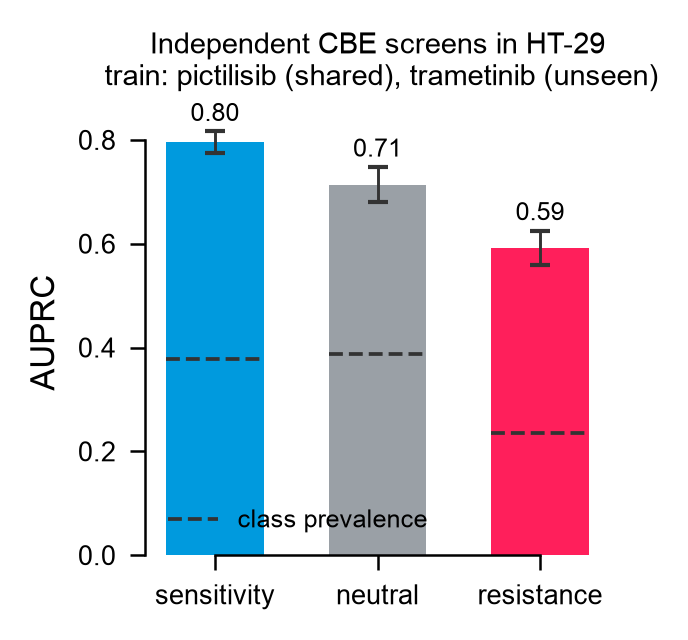

In [169]:
fig, ax = plt.subplots(figsize=(2, 2))

positions = np.arange(len(CLASSES))

ax.bar(positions, means, yerr=errors, width=0.6, linewidth=0, capsize=2.5,
       color=[CLASS_COLOUR[name] for name in CLASSES],
       error_kw=dict(lw=0.7, ecolor="#333333"))

for position, name in zip(positions, CLASSES):
    ax.hlines(down_prevalence[name], position - 0.3, position + 0.3, color="#333333",
              lw=0.9, ls="--")
    ax.text(position, means[name] + errors[name] + 0.02, f"{means[name]:.2f}",
            ha="center", fontsize=6)

ax.set_xticks(positions)
ax.set_xticklabels(CLASSES, fontsize=7)
ax.set_ylabel("AUPRC")
ax.set_title("Independent CBE screens in HT-29\n train: pictilisib (shared), trametinib (unseen)",
             fontsize=7)

ax.tick_params(labelsize=6.5)
ax.plot([], [], color="#333333", lw=0.9, ls="--", label="class prevalence")
ax.legend(frameon=False, fontsize=6, loc="lower left")
fig.tight_layout(pad=0.3)

save_plot(fig, "model_external_auprc")
plt.show()

## SHAP


In [137]:
SHAP_SEED = 0
attributions, observed = [], []

for draw in range(DRAWS):
    block_s = downsample(training, draw).reset_index(drop=True)
    labels_s = block_s.call.map(CLASS_INDEX).to_numpy()
    matrix = block_s[ALL_FEATURES].astype(float)
    keys = pd.MultiIndex.from_frame(block_s[["guide", "cell_line", "compound"]])
    splitter = StratifiedGroupKFold(FOLDS, shuffle=True, random_state=SHAP_SEED)
    for train, test in splitter.split(matrix.to_numpy(), labels_s, groups=block_s[GROUP_UNIT]):
        model = fit_model(matrix.to_numpy()[train], labels_s[train], SHAP_SEED)
        # shap returns (rows, features, classes) for multiclass trees
        values = np.asarray(shap.TreeExplainer(model).shap_values(matrix.iloc[test]))
        if values.ndim != 3:
            values = np.stack(list(values), axis=-1)
        for index, name in enumerate(CLASSES):
            attributions.append(
                pd.DataFrame(values[:, :, index], index=keys[test], columns=ALL_FEATURES)
                .assign(**{"class": name})
            )
        observed.append(matrix.iloc[test].set_axis(keys[test]))

KEY = ["guide", "cell_line", "compound"]
attributions = pd.concat(attributions).rename_axis(KEY).reset_index()
observed = pd.concat(observed).rename_axis(KEY)
observed = observed[~observed.index.duplicated()]
print(f"{len(observed):,} distinct rows carry an out-of-fold attribution")

7,961 distinct rows carry an out-of-fold attribution


In [ ]:
averaged = attributions.groupby(["class", *KEY])[ALL_FEATURES].mean()

ROW_KEYS = list(observed.index)
SHAP_MATRIX = {
    name: averaged.loc[name].reindex(observed.index).to_numpy() for name in CLASSES
}

shap_features = observed.reset_index(drop=True)

shap_meta = (
    training.set_index(["guide", "cell_line", "compound"])
    .loc[ROW_KEYS, ["call", "category", "gene"]]
    .reset_index()[["call", "category", "gene", "cell_line", "compound"]]
)

print(f"one attribution matrix per class, each {SHAP_MATRIX['resistance'].shape}")

one attribution matrix per class, each (7961, 83)


In [139]:
importance = pd.DataFrame(
    {name: np.abs(SHAP_MATRIX[name]).mean(axis=0) for name in CLASSES},
    index=ALL_FEATURES,
)
importance["mean"] = importance[CLASSES].mean(axis=1)
importance = importance.sort_values("mean", ascending=False)
importance.head(15)

,sensitivity,neutral,resistance,mean
ln_ic50,0.282397,0.205924,0.255859,0.248060
crispr_gene_effect,0.327086,0.122667,0.090715,0.180156
expression_tpm_log2,0.214831,0.027315,0.129188,0.123778
copy_number,0.128037,0.036051,0.100741,0.088276
protein_abundance,0.157977,0.057113,0.038258,0.084449
string_distance,0.099965,0.019274,0.023816,0.047685
vep_BayesDel_noAF_score,0.017780,0.081926,0.014297,0.038001
vep_GPN_MSA_score,0.008294,0.064406,0.035926,0.036209
vep_MPC_score,0.051374,0.027964,0.028859,0.036066
vep_MAX_AF,0.032979,0.034979,0.022207,0.030055


In [140]:
def feature_group(column):
    """Which block a feature belongs to, using the groups the export defines."""
    for name, columns in GROUP_OF:
        if column in set(columns):
            return name
    return "other"


FEATURE_GROUPS = ["cellular", "drug", "annotation", "protvar"]
importance["group"] = [feature_group(column) for column in importance.index]
importance.group.value_counts().reindex(FEATURE_GROUPS).rename("features").to_frame()

,features
group,
cellular,4
drug,3
annotation,74
protvar,2


### SHAP against XGBoost's GAIN


In [ ]:
whole = downsample(training, 0)
gain_model = fit_model(
    whole[ALL_FEATURES].astype(float).to_numpy(),
    whole.call.map(CLASS_INDEX).to_numpy(),
    0,
)
comparison = pd.DataFrame(
    {
        "xgboost_gain": gain_model.feature_importances_,
        "shap_mean_abs": importance["mean"].reindex(ALL_FEATURES).to_numpy(),
    },
    index=ALL_FEATURES,
)
comparison["group"] = [
    "context" if column in set(CONTEXT_FEATURES) else "perturbation"
    for column in comparison.index
]

In [142]:
spearman = comparison.xgboost_gain.corr(comparison.shap_mean_abs, method="spearman")
pearson = comparison.xgboost_gain.corr(comparison.shap_mean_abs)
print(f"over {len(comparison)} features: Spearman {spearman:.3f}, Pearson {pearson:.3f}")
for group, block in comparison.groupby("group"):
    print(f"  {group:13s} Spearman "
          f"{block.xgboost_gain.corr(block.shap_mean_abs, method='spearman'):.3f} "
          f"({len(block)} features)")

over 83 features: Spearman 0.648, Pearson 0.473
  context       Spearman 0.500 (7 features)
  perturbation  Spearman 0.598 (76 features)


In [ ]:
top_gain = set(comparison.xgboost_gain.sort_values(ascending=False).head(15).index)
top_shap = set(comparison.shap_mean_abs.sort_values(ascending=False).head(15).index)
print(f"{len(top_gain & top_shap)} of the top 15 features are shared")

disagreement = pd.DataFrame(
    {
        "ranked by gain only": pd.Series(
            sorted(c.replace("vep_", "") for c in top_gain - top_shap)
        ),
        "ranked by SHAP only": pd.Series(
            sorted(c.replace("vep_", "") for c in top_shap - top_gain)
        ),
    }
).fillna("")
disagreement

9 of the top 15 features are shared


,ranked by gain only,ranked by SHAP only
0,MutScore_score,DANN_score
1,am_class_likely_benign,MAX_AF
2,am_pathogenicity,MPC_score
3,consequence_splice_acceptor_variant,PHACTboost_score
4,impact_HIGH,plddt
5,impact_LOW,spliceai_ds_ag


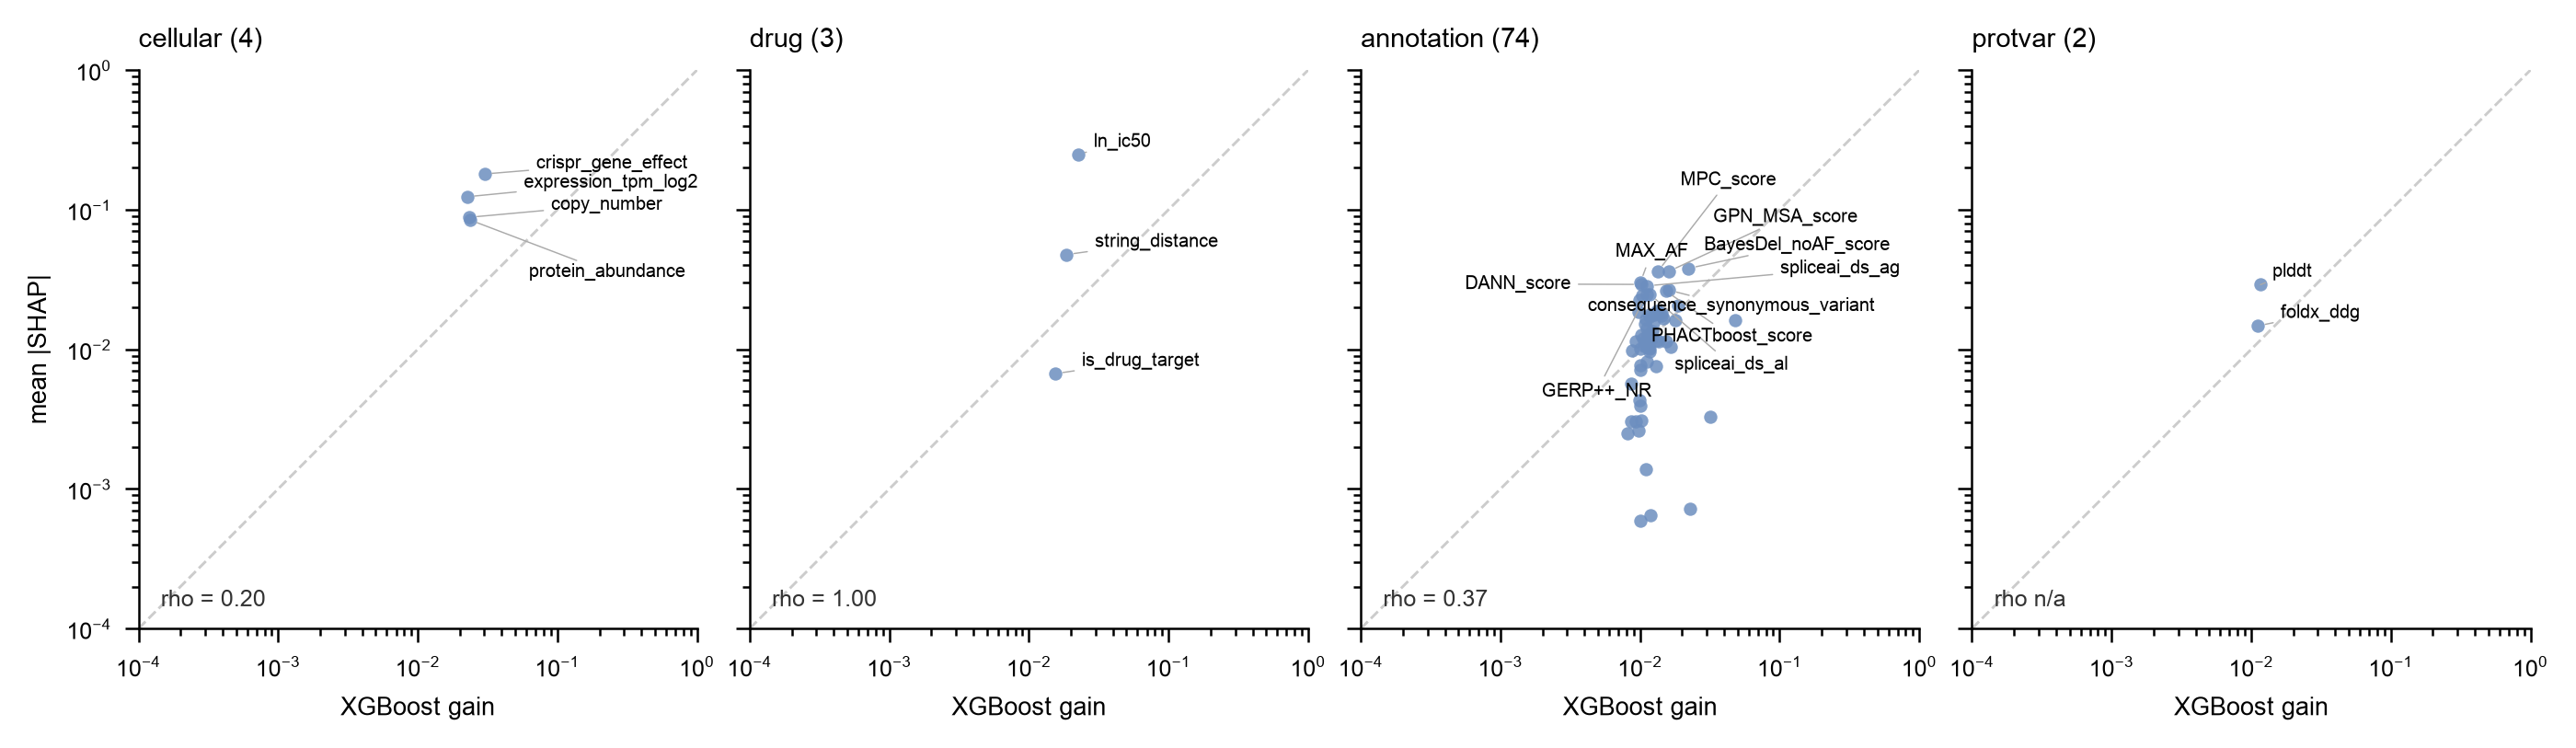

In [144]:
comparison["group"] = [feature_group(column) for column in comparison.index]
positive = comparison[(comparison.xgboost_gain > 0) & (comparison.shap_mean_abs > 0)]
bottom = 10.0 ** np.floor(np.log10(min(positive.xgboost_gain.min(),
                                       positive.shap_mean_abs.min())))
top = 10.0 ** np.ceil(np.log10(max(positive.xgboost_gain.max(),
                                   positive.shap_mean_abs.max())))
shown = [g for g in FEATURE_GROUPS if (comparison.group == g).any()]

fig, axes = plt.subplots(1, len(shown), figsize=(2.3 * len(shown), 2.7),
                         sharex=True, sharey=True)
for ax, group in zip(np.atleast_1d(axes), shown):
    block = comparison[comparison.group == group]
    usable = block[(block.xgboost_gain > 0) & (block.shap_mean_abs > 0)]
    ax.plot([bottom, top], [bottom, top], color="#cccccc", lw=0.7, ls="--", zorder=0)
    ax.scatter(block.xgboost_gain, block.shap_mean_abs, s=12, linewidths=0,
               color="#6c8ebf", alpha=0.85)
    labels = [
        ax.text(row.xgboost_gain, row.shap_mean_abs, feature.replace("vep_", ""),
                fontsize=4.8)
        for feature, row in usable.sort_values("shap_mean_abs", ascending=False).head(10).iterrows()
    ]
    adjust_text(labels, ax=ax, expand=(1.2, 1.4), force_text=(0.4, 0.6),
                arrowprops=dict(arrowstyle="-", color="#aaaaaa", lw=0.35))
    inside = (
        usable.xgboost_gain.corr(usable.shap_mean_abs, method="spearman")
        if len(usable) > 2 else np.nan
    )
    ax.annotate(
        f"rho = {inside:.2f}" if np.isfinite(inside) else "rho n/a",
        xy=(0.04, 0.04), xycoords="axes fraction", fontsize=6, color="#333333",
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(bottom, top)
    ax.set_ylim(bottom, top)
    ax.set_box_aspect(1)
    ax.set_title(f"{group} ({len(block)})", fontsize=7, loc="left")
    ax.set_xlabel("XGBoost gain", fontsize=6.5)
    ax.tick_params(labelsize=6)
np.atleast_1d(axes)[0].set_ylabel("mean |SHAP|", fontsize=6.5)
fig.tight_layout(pad=0.3)
save_plot(fig, "model_shap_vs_gain")
plt.show()

### Beeswarm of the top ten features, one panel per class


In [145]:
TOP_TEN = {
    name: list(importance[name].sort_values(ascending=False).head(10).index)
    for name in CLASSES
}
pd.DataFrame(TOP_TEN).rename(lambda rank: rank + 1).rename_axis("rank")

,sensitivity,neutral,resistance
rank,,,
1,crispr_gene_effect,ln_ic50,ln_ic50
2,ln_ic50,crispr_gene_effect,expression_tpm_log2
3,expression_tpm_log2,vep_BayesDel_noAF_score,copy_number
4,protein_abundance,vep_GPN_MSA_score,crispr_gene_effect
5,copy_number,protein_abundance,vep_GERP++_NR
6,string_distance,plddt,spliceai_ds_al
7,vep_DANN_score,spliceai_ds_ag,protein_abundance
8,vep_MPC_score,consequence_synonymous_variant,vep_GPN_MSA_score
9,vep_phastCons17way_primate,impact_HIGH,consequence_synonymous_variant


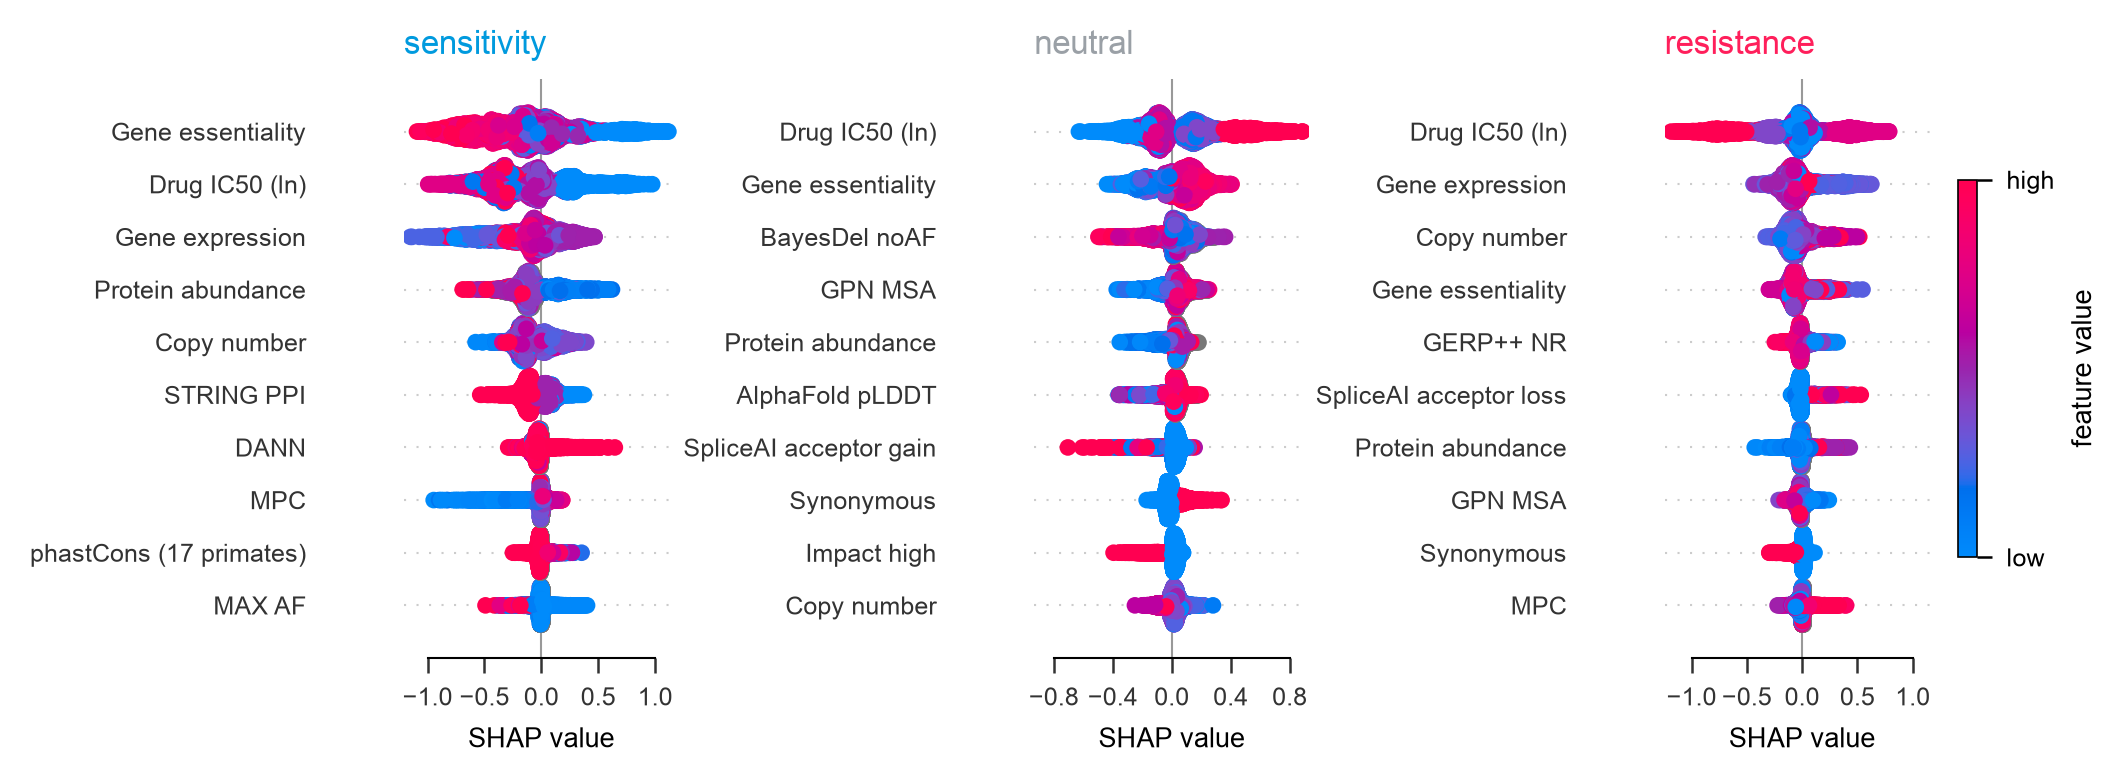

In [178]:
LABELS = {
    # cellular and drug context
    "expression_tpm_log2": "Gene expression",
    "copy_number": "Copy number",
    "crispr_gene_effect": "Gene essentiality",
    "protein_abundance": "Protein abundance",
    "ln_ic50": "Drug IC50 (ln)",
    "string_distance": "STRING PPI",
    "is_drug_target": "Gene is drug target",
    # structure and substitution
    "foldx_ddg": "FoldX ddG",
    "plddt": "AlphaFold pLDDT",
    "pocket_score": "Pocket score",
    "pocket_buriedness": "Pocket buriedness",
    "in_predicted_pocket": "In predicted pocket",
    "interface_count": "Interface contacts",
    "is_in_interface": "At an interface",
    "blosum62": "BLOSUM62",
    # splice
    "splice_scored": "SpliceAI scored",
    "spliceai_ds_ag": "SpliceAI acceptor gain",
    "spliceai_ds_al": "SpliceAI acceptor loss",
    "spliceai_ds_dg": "SpliceAI donor gain",
    "spliceai_ds_dl": "SpliceAI donor loss",
    "am_pathogenicity": "AlphaMissense",
    "phastCons17way_primate": "phastCons (17 primates)",
    "phastCons100way_vertebrate": "phastCons (100 vertebrates)",
    "phyloP17way_primate": "phyloP (17 primates)",
    "phyloP100way_vertebrate": "phyloP (100 vertebrates)",
    "phyloP470way_mammalian": "phyloP (470 mammals)",
    "GERP_92_mammals": "GERP (92 mammals)",
    "GERP++_RS": "GERP++ RS",
    "GERP++_NR": "GERP++ NR",
}
PREFIXES = {
    "consequence_": "",                 # the level already names the consequence
    "impact_": "Impact ",
    "am_class_": "AlphaMissense ",
}


def pretty(column):
    """A readable axis label for a feature name."""
    stem = column.replace("vep_", "")
    if stem in LABELS:
        return LABELS[stem]
    for prefix, replacement in PREFIXES.items():
        if stem.startswith(prefix):
            level = stem[len(prefix):].replace("_variant", "").replace("_", " ")
            return (replacement + level).strip().capitalize()
    # dbNSFP predictors: drop the scoring suffix, which is the same for all of them
    stem = re.sub(r"_(converted_)?(rank)?score$", "", stem)
    return stem.replace("_", " ")


pd.Series({c: pretty(c) for c in ALL_FEATURES}, name="label").to_frame().head(20)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, name in zip(axes, CLASSES):
    top = TOP_TEN[name]
    positions = [ALL_FEATURES.index(column) for column in top]
    explanation = shap.Explanation(
        values=SHAP_MATRIX[name][:, positions],
        data=shap_features[top].to_numpy(),
        feature_names=[pretty(column) for column in top],
    )
    plt.sca(ax)
    shap.plots.beeswarm(explanation, max_display=10, show=False, color_bar=False,
                        plot_size=None)
    # centre the axis on zero, so the sign of a contribution reads the same either side
    limit = np.abs(explanation.values).max() * 1.05
    ax.set_xlim(-limit, limit)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5, symmetric=True))
    ax.set_title(name, fontsize=8, loc="left", color=CLASS_COLOUR[name])
    ax.tick_params(labelsize=6)
    ax.set_xlabel("SHAP value", fontsize=6.5)
    # shap draws a heavy axis line at zero; thin it so it does not dominate the panel
    for line in ax.get_lines():
        if line.get_linestyle() in {"-", "solid"}:
            line.set_linewidth(0.5)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)

fig.tight_layout(pad=0.4, rect=(0, 0, 0.94, 1))
scale = plt.cm.ScalarMappable(cmap=shap.plots.colors.red_blue)
bar = fig.colorbar(scale, ax=axes, fraction=0.012, pad=0.012, ticks=[0, 1])
bar.ax.set_yticklabels(["low", "high"], fontsize=6)
bar.set_label("feature value", fontsize=6.5)
bar.outline.set_linewidth(0.4)

save_plot(fig, "model_shap_beeswarm")
plt.show()

### Sensitivity against resistance importance


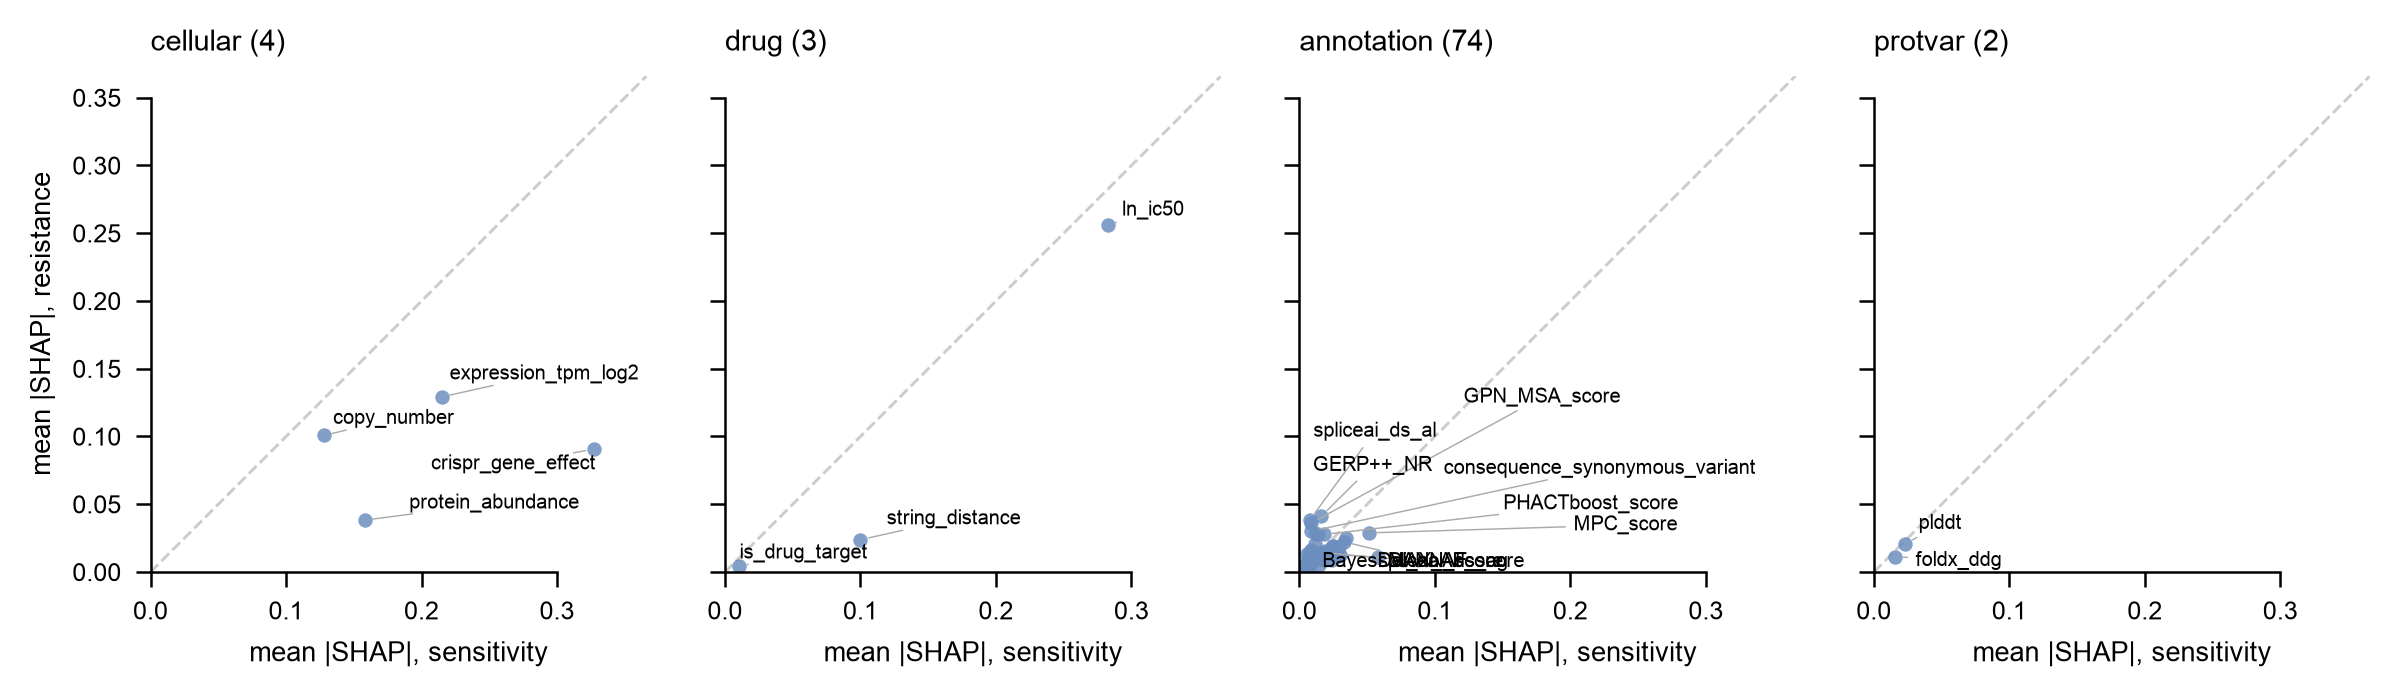

In [179]:
present = [g for g in FEATURE_GROUPS if (importance.group == g).any()]
# one shared range across the panels, so a point's height means the same thing in each
span = float(importance[["sensitivity", "resistance"]].to_numpy().max()) * 1.12

fig, axes = plt.subplots(1, len(present), figsize=(2 * len(present), 2),
                         sharex=True, sharey=True)
for ax, group in zip(np.atleast_1d(axes), present):
    block = importance[importance.group == group]
    ax.plot([0, span], [0, span], color="#cccccc", lw=0.7, ls="--", zorder=0)
    ax.scatter(block.sensitivity, block.resistance, s=12, linewidths=0,
               color="#6c8ebf", alpha=0.85)
    labels = [
        ax.text(row.sensitivity, row.resistance, feature.replace("vep_", ""), fontsize=4.8)
        for feature, row in block.sort_values("mean", ascending=False).head(10).iterrows()
    ]
    adjust_text(labels, ax=ax, expand=(1.2, 1.4), force_text=(0.4, 0.6),
                arrowprops=dict(arrowstyle="-", color="#aaaaaa", lw=0.35))
    ax.set_xlim(0, span)
    ax.set_ylim(0, span)
    ax.set_box_aspect(1)
    ax.set_title(f"{group} ({len(block)})", fontsize=7, loc="left")
    ax.set_xlabel("mean |SHAP|, sensitivity", fontsize=6.5)
    ax.tick_params(labelsize=6)
np.atleast_1d(axes)[0].set_ylabel("mean |SHAP|, resistance", fontsize=6.5)
fig.tight_layout(pad=0.3)
save_plot(fig, "model_shap_sensitivity_vs_resistance")
plt.show()

### UMAP


In [180]:
def decision_space(columns):
    positions = [ALL_FEATURES.index(column) for column in columns]
    blocks = []
    for name in CLASSES:
        part = SHAP_MATRIX[name][:, positions]
        scale = np.abs(part).mean()
        blocks.append(part / scale if scale else part)
    return np.hstack(blocks)


def embed(columns):
    space = decision_space(columns)
    points = umap.UMAP(
        n_neighbors=30, min_dist=0.1, metric="euclidean", random_state=0
    ).fit_transform(space)
    return pd.DataFrame(points, columns=["umap_1", "umap_2"]), space.shape

In [149]:
all_embedding, all_shape = embed(ALL_FEATURES)
perturbation_embedding, perturbation_shape = embed(PERTURBATION_FEATURES)
print(f"all features: {all_shape}, perturbation only: {perturbation_shape}")

/Users/emanuel/miniconda3/envs/becr/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/emanuel/miniconda3/envs/becr/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


all features: (7961, 249), perturbation only: (7961, 228)


In [150]:
TOP_THREE = list(
    importance.loc[[c for c in importance.index if c in set(PERTURBATION_FEATURES)]]
    .head(3)
    .index
)
COMPOUND_COLOUR = dict(
    zip(sorted(shap_meta.compound.unique()), ["#1f4e76", "#d1702a", "#3f8f6b"])
)
print("coloured by:", [c.replace("vep_", "") for c in TOP_THREE])

coloured by: ['BayesDel_noAF_score', 'GPN_MSA_score', 'MPC_score']


/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/716194251.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.2)


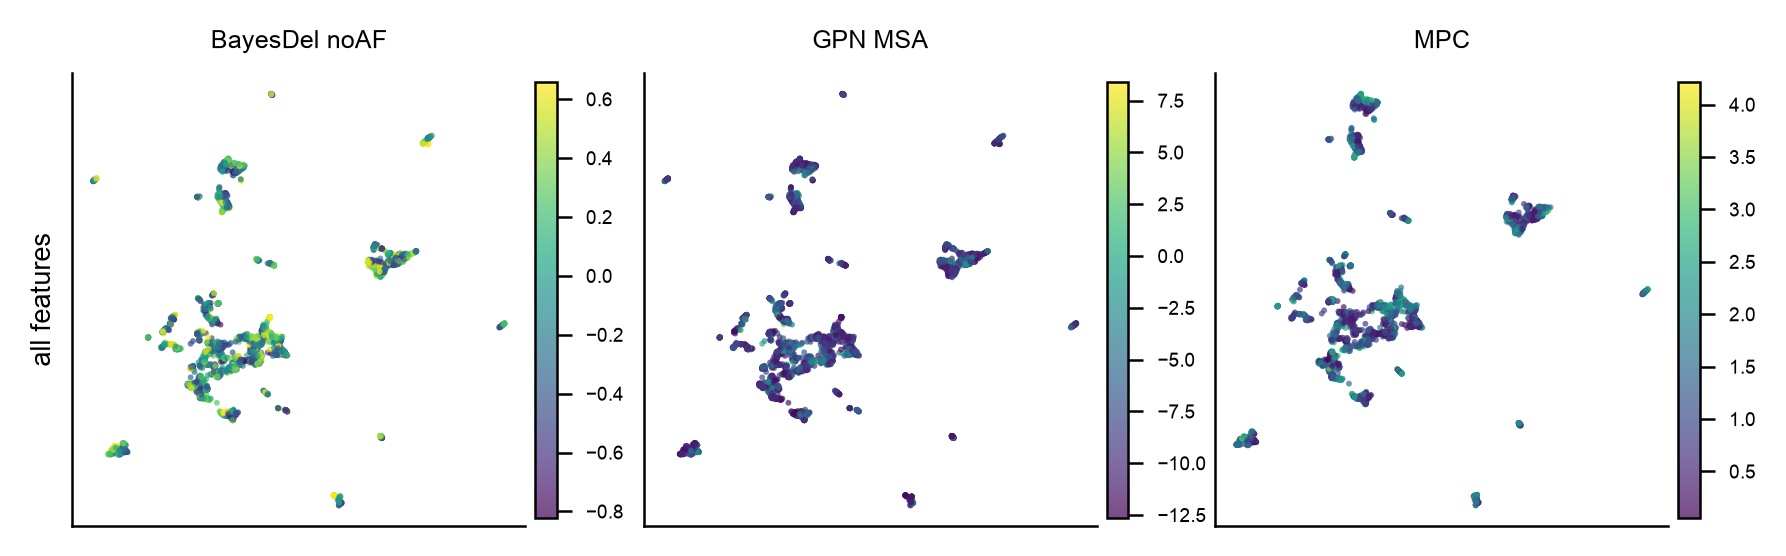

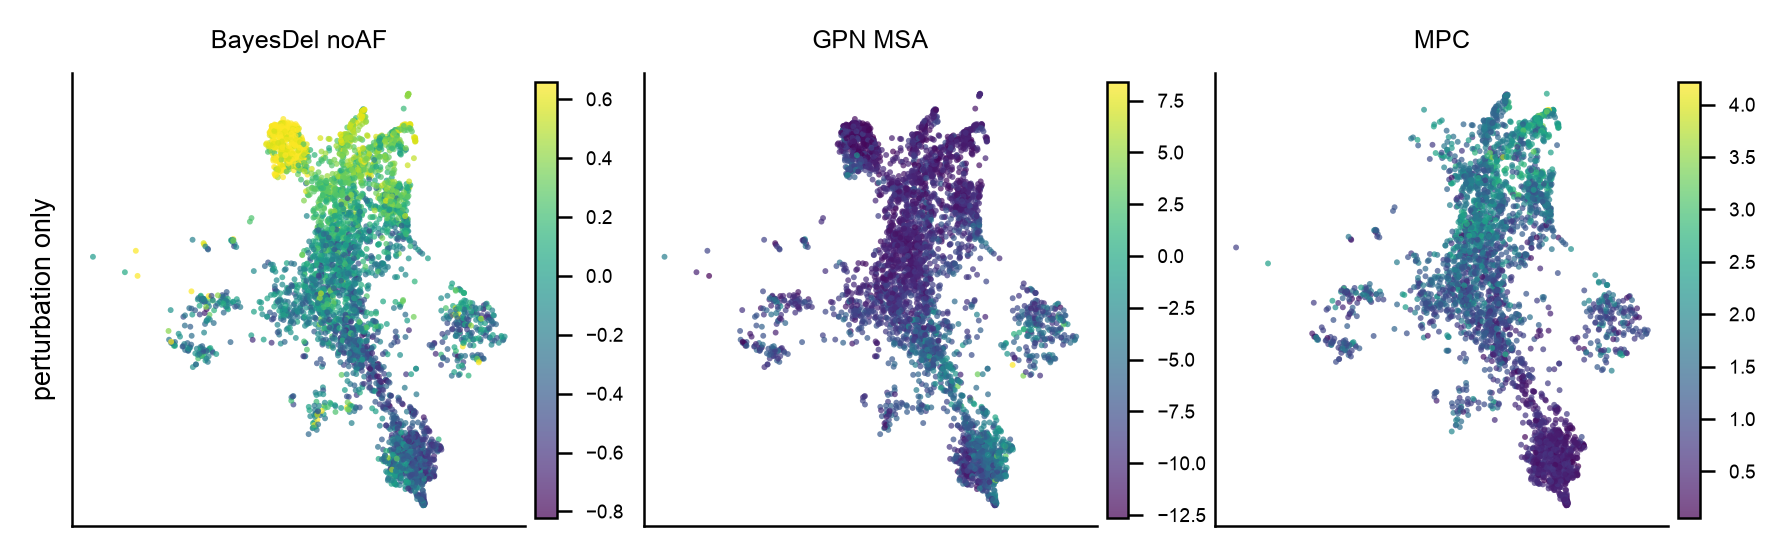

In [198]:
EMBEDDINGS = [
    (all_embedding, "all features", "model_shap_umap_features_all"),
    (perturbation_embedding, "perturbation only", "model_shap_umap_features_perturbation"),
]

for embedding, label, name in EMBEDDINGS:
    fig, axes = plt.subplots(1, 3, figsize=(7, 3),
                             gridspec_kw=dict(wspace=0.18))
    
    for ax, column in zip(axes, TOP_THREE):
        values = pd.to_numeric(shap_features[column], errors="coerce")
        points = ax.scatter(embedding.umap_1, embedding.umap_2, c=values, s=2,
                            linewidths=0, cmap="viridis", alpha=0.7, rasterized=True)
        fig.colorbar(points, ax=ax, fraction=0.045, pad=0.02).ax.tick_params(labelsize=4.5)
        ax.set_title(pretty(column), fontsize=6)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_box_aspect(1)
    
    axes[0].set_ylabel(label, fontsize=6.5)
    
    fig.tight_layout(pad=0.2)
    
    save_plot(fig, name)
    plt.show()

In [186]:
from src import ARM_COLOUR

ARM_OF = {label.lower(): code for code, label in C.ARM_LABEL.items()}
condition = shap_meta.cell_line + " " + shap_meta.compound
CONDITION_COLOUR = {
    f"{cell} {compound}": ARM_COLOUR[(cell, ARM_OF[compound.lower()])]
    for cell in shap_meta.cell_line.unique()
    for compound in shap_meta.compound.unique()
}
CONDITION_COLOUR

{'A375 linsitinib': '#0072B2',
 'A375 pictilisib': '#619FD1',
 'A375 SCH772984': '#A7C9E7',
 'HT29 linsitinib': '#D55E00',
 'HT29 pictilisib': '#F79A6A',
 'HT29 SCH772984': '#FFD9C6'}

In [196]:
def category_panel(ax, embedding, values, palette, legend, fontsize=4.2):
    """Scatter one embedding coloured by a categorical column."""
    for level, colour in palette.items():
        mask = (values == level).to_numpy()
        ax.scatter(embedding.umap_1[mask], embedding.umap_2[mask], s=2, linewidths=0,
                   color=colour, label=level, alpha=0.8, rasterized=True)
    if legend:
        ax.legend(fontsize=fontsize, markerscale=1.8, frameon=True,
                  framealpha=0.75, edgecolor="none", borderpad=0.2,
                  labelspacing=0.25, handletextpad=0.3)

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3450265101.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.2)


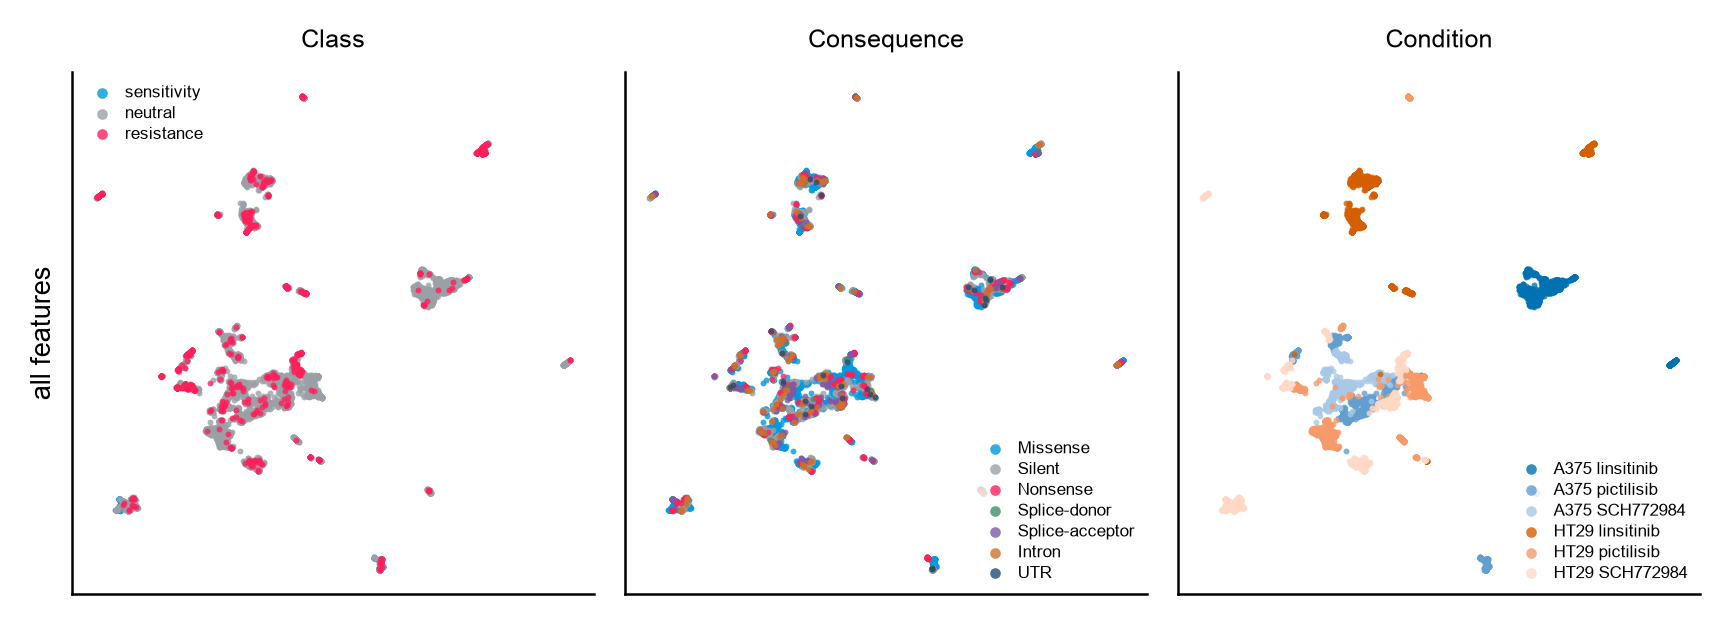

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_74358/3450265101.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.2)


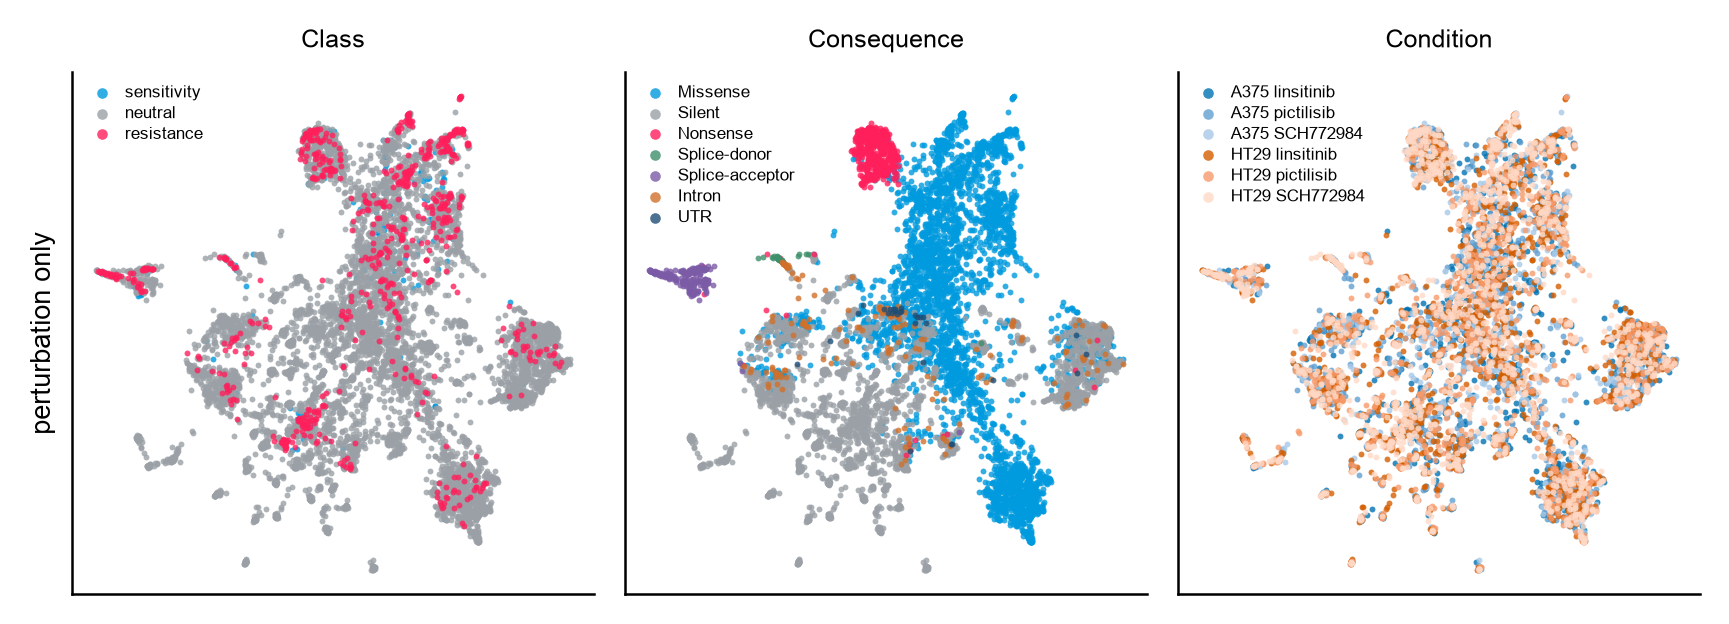

In [199]:
GROUPINGS = [
    (shap_meta.call, CLASS_COLOUR, "Class"),
    (shap_meta.category,
     {c: CATEGORY_COLOUR[c] for c in CATEGORY_ORDER if c in set(shap_meta.category)},
     "Consequence"),
    (condition, CONDITION_COLOUR, "Condition"),
]
EMBEDDINGS = [
    (all_embedding, "all features", "model_shap_umap_all"),
    (perturbation_embedding, "perturbation only", "model_shap_umap_perturbation"),
]

for embedding, label, name in EMBEDDINGS:
    fig, axes = plt.subplots(1, 3, figsize=(7, 3), gridspec_kw=dict(wspace=0.06))
    
    for ax, (values, palette, title) in zip(axes, GROUPINGS):
        category_panel(ax, embedding, values, palette, legend=True)
        ax.set_title(title, fontsize=6)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_box_aspect(1)
    
    axes[0].set_ylabel(label, fontsize=6.5)
    
    fig.tight_layout(pad=0.2)
    save_plot(fig, name)
    plt.show()